# Alpha decay: where are the "textbook" signals today?

Reproduces every number, table and figure of the article. Single input: `data/alpha_decay_data.csv`
(monthly, 1926-02 to 2026-09, 47 columns; see `README.md` for the data dictionary and sources).
All series are long-short returns in **percent per month**, gross of costs.

Run top to bottom (`Kernel > Restart & Run All`). Runtime is about two minutes, most of it the bootstrap in section 6.

| Section | Content |
|---|---|
| 1 | Setup and data |
| 2 | Constructed strategies: FX carry, diversified trend, US equity trend, Faber rule |
| 3 | Signal panel and original-paper metadata |
| 4 | Statistics: windows, Sharpe, HAC t, break tests |
| 5 | Table 1 and per-signal summary |
| 6 | Structural breaks (Quandt-Andrews, block bootstrap) |
| 7 | Pooled decay regressions (McLean-Pontiff design) and robustness |
| 8 | Event study, basket by decade, power |
| 9 | Crowding proxies |
| 10 | Figures 1 to 6 |
| 11 | Hero image |

## 1. Setup and data

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
warnings.filterwarnings("ignore")

DATA = "data/alpha_decay_data.csv"
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
NBOOT = 1000          # bootstrap draws for the structural-break tests

NAVY, GOLD, GREY, RED = "#0E1020", "#B8860B", "#8A8F9C", "#B23A48"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.facecolor": "white", "axes.facecolor": "white"})
pd.set_option("display.width", 220, "display.max_columns", 40)

raw = pd.read_csv(DATA, dtype={"date": str})
raw.index = pd.PeriodIndex(raw["date"], freq="M")
raw = raw.drop(columns="date")
rf, mkt = raw["rf"], raw["mkt_rf"]
END = raw.index.max()
print(raw.shape, raw.index.min(), "->", END)
raw.notna().sum().to_frame("non-missing").T

(1208, 47) 1926-02 -> 2026-09


,mkt_rf,smb,hml,rmw,cma,umd,str,ltr,rf,bab_us,bab_xus,qmj_us,qmj_xus,hmld_us,hmld_xus,val_all,mom_all,val_ss,mom_ss,val_aa,...,fx_nok_ret,fx_sek_ret,fx_eur_ret,fx_aud_rd,fx_cad_rd,fx_chf_rd,fx_jpy_rd,fx_gbp_rd,fx_nzd_rd,fx_nok_rd,fx_sek_rd,fx_eur_rd,bond_2y_ret,bond_5y_ret,bond_10y_ret,bond_30y_ret,oil_wti_ret,oil_brent_ret,chf_call_rd,jpy_call_rd
non-missing,1203,1203,1203,759,759,1197,1208,1149,1203,1149,475,830,446,1149,506,656,656,655,656,637,...,668,668,669,668,669,327,293,661,634,573,537,669,603,669,669,595,488,472,627,495


## 2. Constructed strategies

Built from the FRED block of the data file.

* **FX carry (G10).** Each month the available currencies (at least seven) are ranked by their 3-month rate differential against the USD (CHF and JPY use call-rate differentials where the 3-month rate is missing). Long the top third, short the bottom third, equal weights, held one month. A currency's excess return is its spot change plus the previous month's differential divided by 12.
* **Diversified trend (TSMOM).** Per market: sign of the trailing 12-month compounded excess return, position scaled to 10% annualised volatility (trailing 36 months, floor 2%), held one month; equal-weighted across at least five markets (9 currencies, 4 Treasury maturities, 2 crude oil benchmarks, US equity).
* **US equity trend.** Same rule on the French market excess return alone (history from 1926). Faber's 10-month moving-average rule is also computed (long the market above its 10-month average, otherwise T-bills).

In [2]:
CCY = ["aud", "cad", "chf", "jpy", "gbp", "nzd", "nok", "sek", "eur"]
mac = raw.loc[raw.index >= pd.Period("1971-01", "M")]

spot = pd.DataFrame({c: mac[f"fx_{c}_ret"] for c in CCY})
rd = pd.DataFrame({c: mac[f"fx_{c}_rd"] for c in CCY})
rd["chf"] = rd["chf"].fillna(mac["chf_call_rd"])      # call-rate basis vs 3m: mean ~1-2bp, sd ~25-30bp
rd["jpy"] = rd["jpy"].fillna(mac["jpy_call_rd"])
fx_ex = spot + rd.shift(1) / 12.0                     # USD-funded excess return, % per month

# ---- FX carry
carry = pd.Series(np.nan, index=mac.index)
for i in range(len(mac.index) - 1):
    t, t1 = mac.index[i], mac.index[i + 1]
    x = rd.loc[t].dropna()
    x = x[fx_ex.loc[t1].reindex(x.index).notna()]
    n = len(x)
    if n < 7:
        continue
    k = n // 3
    r = x.sort_values()
    e = fx_ex.loc[t1]
    carry[t1] = e[r.index[-k:]].mean() - e[r.index[:k]].mean()

# ---- time-series momentum
mk = pd.DataFrame(index=mac.index)
for c in CCY:
    mk[f"fx_{c}"] = fx_ex[c]
for m in ["2y", "5y", "10y", "30y"]:
    mk[f"bond_{m}"] = mac[f"bond_{m}_ret"] - rf.reindex(mac.index)
mk["oil_wti"], mk["oil_brent"] = mac["oil_wti_ret"], mac["oil_brent_ret"]

def tsmom_legs(R, lookback=12, vol_win=36, target=10.0, floor=2.0):
    lr = np.log1p(R / 100.0)
    sgn = np.sign(lr.rolling(lookback, min_periods=lookback).sum())
    vol = (R.rolling(vol_win, min_periods=24).std() * np.sqrt(12)).clip(lower=floor)
    return (sgn * (target / vol)).shift(1) * R

legs = pd.concat([tsmom_legs(mk), tsmom_legs(pd.DataFrame({"eq_us": mkt}))], axis=1)
grp = {"tsmom_fx": [c for c in legs if c.startswith("fx_")], "tsmom_bond": [c for c in legs if c.startswith("bond_")],
       "tsmom_oil": [c for c in legs if c.startswith("oil_")], "tsmom": list(legs.columns)}
cons = pd.DataFrame(index=legs.index)
cnt = legs.notna().sum(axis=1)
for g, cols in grp.items():
    cons[g] = legs[cols].mean(axis=1, skipna=True)
cons.loc[cnt < 5, "tsmom"] = np.nan
cons.loc[legs[grp["tsmom_fx"]].notna().sum(axis=1) < 2, "tsmom_fx"] = np.nan
cons["fx_carry"] = carry

# ---- US equity trend (12m sign, vol targeted) and Faber 10-month rule
eq_trend = tsmom_legs(pd.DataFrame({"eq_trend": mkt}))["eq_trend"]
tr = (1 + (mkt + rf) / 100).cumprod()
faber_sig = (tr > tr.rolling(10).mean()).astype(float).shift(1)
eq_faber = (faber_sig * mkt).where(faber_sig.notna())
constructed = pd.concat([cons, eq_trend, eq_faber.rename("eq_faber"), mkt.rename("eq_buyhold")], axis=1)
constructed.describe().T[["count", "mean", "std"]].round(2)

,count,mean,std
tsmom_fx,644.0,0.23,1.99
tsmom_bond,645.0,0.38,2.69
tsmom_oil,464.0,0.00,3.40
tsmom,644.0,0.26,1.57
fx_carry,572.0,0.33,2.47
eq_trend,1179.0,0.33,3.19
eq_faber,1203.0,0.57,3.60
eq_buyhold,1203.0,0.69,5.30


## 3. Signal panel and original-paper metadata

In [3]:
sig = pd.concat([raw[["smb", "hml", "umd", "str", "ltr", "rmw", "cma", "bab_us", "bab_xus", "qmj_us", "qmj_xus",
                      "hmld_us", "hmld_xus", "val_all", "mom_all", "val_ss", "mom_ss", "val_aa", "mom_aa"]],
                 constructed], axis=1)

# name -> (label, journal year, original sample start, original sample end, citation)
META = {
    "smb":      ("Size (SMB)",                          1981, 1936, 1975, "Banz (1981)"),
    "hml":      ("Value (HML)",                         1992, 1963, 1990, "Fama-French (1992)"),
    "hmld_us":  ("Value, current prices (HML Devil)",   2013, 1950, 2011, "Asness-Frazzini (2013)"),
    "umd":      ("Momentum (UMD)",                      1993, 1965, 1989, "Jegadeesh-Titman (1993)"),
    "str":      ("Short-term reversal",                 1990, 1934, 1987, "Jegadeesh (1990)"),
    "ltr":      ("Long-term reversal",                  1985, 1926, 1982, "De Bondt-Thaler (1985)"),
    "rmw":      ("Profitability (RMW)",                 2013, 1963, 2010, "Novy-Marx (2013)"),
    "cma":      ("Investment (CMA)",                    2008, 1968, 2003, "Cooper-Gulen-Schill (2008)"),
    "bab_us":   ("Betting against beta, US",            2014, 1926, 2012, "Frazzini-Pedersen (2014)"),
    "bab_xus":  ("Betting against beta, ex-US",         2014, 1926, 2012, "Frazzini-Pedersen (2014)"),
    "qmj_us":   ("Quality minus junk, US",              2019, 1957, 2016, "Asness-Frazzini-Pedersen (2019)"),
    "qmj_xus":  ("Quality minus junk, ex-US",           2019, 1957, 2016, "Asness-Frazzini-Pedersen (2019)"),
    "val_all":  ("Value everywhere",                    2013, 1972, 2011, "Asness-Moskowitz-Pedersen (2013)"),
    "mom_all":  ("Momentum everywhere",                 2013, 1972, 2011, "Asness-Moskowitz-Pedersen (2013)"),
    "tsmom":    ("Time-series momentum (16 markets)",   2012, 1985, 2009, "Moskowitz-Ooi-Pedersen (2012)"),
    "eq_trend": ("US equity trend (12m sign)",          2007, 1973, 2005, "Faber (2007)"),
    "fx_carry": ("FX carry (G10)",                      2007, 1953, 2002, "Lustig-Verdelhan (2007)"),
}
# earliest public circulation (working paper) where it differs materially from the journal year
EARLY = {"rmw": 2010, "bab_us": 2010, "bab_xus": 2010, "qmj_us": 2013, "qmj_xus": 2013,
         "tsmom": 2010, "eq_trend": 2006, "cma": 2004, "hmld_us": 2012}
KEYS = [k for k in META if k in sig.columns]
CORE = ["smb", "hml", "umd", "str", "ltr", "rmw", "cma", "bab_us", "qmj_us", "hmld_us", "tsmom", "eq_trend", "fx_carry"]
print(len(KEYS), "series;", len(CORE), "core signals")

17 series; 13 core signals


## 4. Statistics

Four windows per series: **pre-sample** (before the original paper's data), **in-sample** (the paper's window), **post-sample** (end of the paper's sample to its publication) and **post-publication** (from January after the journal year, the McLean-Pontiff convention). t-statistics use Newey-West errors with 6 lags.

In [4]:
def sharpe(x):
    x = x.dropna()
    return np.nan if len(x) < 24 or x.std() == 0 else x.mean() / x.std() * np.sqrt(12)

def tstat(x, lags=6):
    x = x.dropna()
    if len(x) < 24:
        return np.nan
    return float(sm.OLS(x.values, np.ones(len(x))).fit(cov_type="HAC", cov_kwds={"maxlags": lags}).tvalues[0])

def seg(x, a, b):
    return x[(x.index >= a) & (x.index <= b)]

def periods(name, meta=None):
    meta = meta or META
    lab, pub, ostart, oend, _ = meta[name]
    s = sig[name].dropna()
    first = max(s.index.min(), pd.Period(f"{ostart}-01", "M"))
    return s, first, pd.Period(f"{oend}-12", "M"), pd.Period(f"{pub + 1}-01", "M")

def summarize(name):
    s, first, is_end, post_start = periods(name)
    lab, pub, ostart, oend, cite = META[name]
    pre, ins = s[s.index < first], seg(s, first, is_end)
    oos, post = seg(s, is_end + 1, post_start - 1), seg(s, post_start, END)
    last10, last5 = s[s.index >= END - 119], s[s.index >= END - 59]
    row = dict(key=name, label=lab, cite=cite, pub=pub, start=str(s.index.min()), end=str(s.index.max()),
               n_pre=len(pre), sr_pre=sharpe(pre), n_is=len(ins), sr_is=sharpe(ins), t_is=tstat(ins),
               n_oos=len(oos), sr_oos=sharpe(oos), n_post=len(post), sr_post=sharpe(post), t_post=tstat(post),
               mean_is=ins.mean(), mean_post=post.mean(), sr_10=sharpe(last10), t_10=tstat(last10), sr_5=sharpe(last5),
               sr_all=sharpe(s), t_all=tstat(s))
    if len(post) >= 24 and len(ins) >= 24:           # post-publication minus in-sample mean, HAC
        y = pd.concat([ins, post]); d = np.r_[np.zeros(len(ins)), np.ones(len(post))]
        m = sm.OLS(y.values, sm.add_constant(d)).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
        row["diff_mean"], row["diff_t"] = float(m.params[1]), float(m.tvalues[1])
    for tag, x in [("is", ins), ("post", post), ("10", last10)]:   # CAPM alpha, % per year
        if len(x) >= 24:
            X = sm.add_constant(mkt.reindex(x.index).values); ok = ~np.isnan(X).any(axis=1)
            m = sm.OLS(x.values[ok], X[ok]).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
            row[f"alpha_{tag}"], row[f"alpha_t_{tag}"], row[f"beta_{tag}"] = float(m.params[0] * 12), float(m.tvalues[0]), float(m.params[1])
    if name in EARLY:                                  # dating sensitivity: earliest circulation
        ps = pd.Period(f"{EARLY[name] + 1}-01", "M")
        row["sr_post_early"], row["sr_is_early"] = sharpe(seg(s, ps, END)), sharpe(seg(s, first, ps - 1))
    return row

def sup_f_boot(x, trim=0.15, nboot=NBOOT, block=12, seed=1):
    # Quandt-Andrews sup-F for one mean shift; p-value from a moving-block bootstrap of the demeaned series
    x = x.dropna().values.astype(float); T = len(x)
    k1, k2 = int(T * trim), int(T * (1 - trim))
    def supf(v):
        c, c2 = np.cumsum(v), np.cumsum(v * v); tot, tot2 = c[-1], c2[-1]
        ks = np.arange(k1, k2); s1 = c[ks - 1]; s2 = tot - s1; n1, n2 = ks, T - ks
        ssr1 = (c2[ks - 1] - s1 ** 2 / n1) + ((tot2 - c2[ks - 1]) - s2 ** 2 / n2)
        F = ((tot2 - tot ** 2 / T) - ssr1) / (ssr1 / (T - 2)); i = int(np.argmax(F))
        return F[i], ks[i]
    F0, k0 = supf(x)
    rng = np.random.default_rng(seed); z = x - x.mean(); nb = int(np.ceil(T / block)); cnt = 0
    for _ in range(nboot):
        st = rng.integers(0, T - block + 1, nb)
        if supf(np.concatenate([z[s:s + block] for s in st])[:T])[0] >= F0:
            cnt += 1
    return F0, k0, (cnt + 1) / (nboot + 1)

def decade_table(keys):
    out = {}
    for k in keys:
        s = sig[k].dropna(); d = {}
        for lo, hi in [(1930, 1939), (1940, 1949), (1950, 1959), (1960, 1969), (1970, 1979), (1980, 1989),
                       (1990, 1999), (2000, 2009), (2010, 2019), (2020, 2026)]:
            x = seg(s, pd.Period(f"{lo}-01", "M"), pd.Period(f"{hi}-12", "M"))
            d[f"{lo}s"] = sharpe(x) if len(x) >= 48 else np.nan
        out[k] = d
    return pd.DataFrame(out).T

## 5. Per-signal summary and Table 1

In [5]:
summ = pd.DataFrame([summarize(k) for k in KEYS]).set_index("key")
summ.to_csv(f"{FIG}/../summary_by_signal.csv")
summ[["label", "pub", "start", "end", "n_is", "sr_is", "t_is", "n_oos", "sr_oos", "n_post", "sr_post", "diff_t", "sr_10", "t_10", "sr_5"]].round(2)

,label,pub,start,end,n_is,sr_is,t_is,n_oos,sr_oos,n_post,sr_post,diff_t,sr_10,t_10,sr_5
key,,,,,,,,,,,,,,,
smb,Size (SMB),1981,1926-07,2026-09,480,0.19,1.10,72,1.42,537,0.01,-0.80,-0.27,-0.87,-0.64
hml,Value (HML),1992,1926-07,2026-09,336,0.61,2.81,24,0.54,405,0.19,-1.07,-0.01,-0.03,0.42
hmld_us,"Value, current prices (HML Devil)",2013,1930-12,2026-08,744,0.32,2.25,24,0.68,152,-0.02,-0.94,0.07,0.20,0.30
umd,Momentum (UMD),1993,1927-01,2026-09,300,0.80,4.32,48,1.24,393,0.27,-1.43,0.22,0.85,0.38
str,Short-term reversal,1990,1926-02,2026-09,648,1.14,7.14,36,0.05,429,0.16,-4.06,-0.08,-0.29,-0.65
ltr,Long-term reversal,1985,1931-01,2026-09,624,0.39,2.46,36,-0.92,489,0.16,-1.39,-0.16,-0.45,0.23
rmw,Profitability (RMW),2013,1963-07,2026-09,570,0.42,2.55,36,0.31,153,0.23,-0.55,0.24,0.85,0.15
cma,Investment (CMA),2008,1963-07,2026-09,432,0.74,3.94,60,-0.28,213,0.04,-2.27,-0.06,-0.17,0.14
bab_us,"Betting against beta, US",2014,1930-12,2026-08,985,0.71,5.16,24,3.64,140,0.45,-1.52,0.33,1.36,0.06


In [6]:
print("Mean Sharpe over the 13 core signals:",
      summ.loc[CORE, ["sr_is", "sr_post", "sr_10"]].mean().round(2).to_dict())
print("All lower post-publication than in-sample:", bool((summ.loc[CORE, "sr_post"] < summ.loc[CORE, "sr_is"]).all()))
print("Series with last-10y t > 1.96:", [k for k in summ.index if summ.loc[k, "t_10"] > 1.96])

short = {"smb": "Size (SMB)", "ltr": "Long-term reversal", "str": "Short-term reversal", "hml": "Value (HML)",
         "umd": "Momentum (UMD)", "eq_trend": "US equity trend", "fx_carry": "FX carry, G10", "cma": "Investment (CMA)",
         "tsmom": "Time-series momentum, 16 markets", "rmw": "Profitability (RMW)", "hmld_us": "Value at current prices (HML Devil)",
         "val_all": "Value everywhere", "mom_all": "Momentum everywhere", "bab_us": "Betting against beta, US",
         "bab_xus": "Betting against beta, ex-US", "qmj_us": "Quality minus junk, US", "qmj_xus": "Quality minus junk, ex-US"}
order = sorted(summ.index, key=lambda k: (summ.loc[k, "pub"], k))
table1 = pd.DataFrame({"Signal": [short[k] for k in order], "Year": summ.loc[order, "pub"].astype(int).values,
                       "In-sample Sharpe": summ.loc[order, "sr_is"].round(2).values,
                       "Post-publication Sharpe": summ.loc[order, "sr_post"].round(2).values,
                       "Last 10 years Sharpe": summ.loc[order, "sr_10"].round(2).values,
                       "t-stat, last 10 years": summ.loc[order, "t_10"].round(1).abs().mul(np.sign(summ.loc[order, "t_10"])).values})
table1.to_csv("table1.csv", index=False)
table1

Mean Sharpe over the 13 core signals: {'sr_is': 0.58, 'sr_post': 0.16, 'sr_10': 0.07}
All lower post-publication than in-sample: True
Series with last-10y t > 1.96: ['bab_xus', 'qmj_xus']


,Signal,Year,In-sample Sharpe,Post-publication Sharpe,Last 10 years Sharpe,"t-stat, last 10 years"
0,Size (SMB),1981,0.19,0.01,-0.27,-0.9
1,Long-term reversal,1985,0.39,0.16,-0.16,-0.4
2,Short-term reversal,1990,1.14,0.16,-0.08,-0.3
3,Value (HML),1992,0.61,0.19,-0.01,-0.0
4,Momentum (UMD),1993,0.80,0.27,0.22,0.9
5,US equity trend,2007,0.32,0.31,0.24,0.7
6,"FX carry, G10",2007,0.54,0.21,0.29,1.2
7,Investment (CMA),2008,0.74,0.04,-0.06,-0.2
8,"Time-series momentum, 16 markets",2012,0.78,0.11,0.01,0.1
9,Value at current prices (HML Devil),2013,0.32,-0.02,0.07,0.2


## 6. Structural breaks

Sup-F for a single mean shift (15% trimming); p-values from a moving-block bootstrap (block length 12) of the demeaned series.

In [7]:
br = {}
for k in KEYS:
    F, k0, p = sup_f_boot(sig[k])
    br[k] = dict(supF=F, break_date=str(sig[k].dropna().index[k0]), p=p)
breaks = pd.DataFrame(br).T
breaks.round(3)

,supF,break_date,p
smb,4.000961,1946-06,0.455544
hml,5.110959,2006-08,0.341658
hmld_us,5.483813,1945-07,0.326673
umd,5.825339,2002-10,0.133866
str,16.309464,1988-08,0.014985
ltr,7.949621,1947-06,0.198801
rmw,3.483099,2000-03,0.654346
cma,6.782712,2004-02,0.243756
bab_us,4.892771,1957-01,0.608392
bab_xus,10.216714,1998-12,0.138861


In [8]:
decade_table(KEYS).round(2)

,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s,2020s
smb,0.53,0.59,-0.14,0.54,0.29,-0.01,-0.15,0.37,-0.03,-0.23
hml,0.15,1.04,0.46,0.51,0.83,0.62,0.01,0.62,-0.30,0.12
hmld_us,0.36,0.82,0.13,0.05,0.90,0.52,-0.34,0.52,-0.35,0.27
umd,-0.01,0.70,1.36,1.17,0.75,0.73,1.21,0.04,0.29,0.24
str,1.17,1.59,1.49,1.14,1.35,0.69,0.16,0.25,0.42,-0.39
ltr,0.50,0.58,-0.51,0.47,0.74,-0.07,0.74,0.44,-0.53,0.24
rmw,NaN,NaN,NaN,0.25,-0.11,0.97,0.39,0.62,0.26,0.21
cma,NaN,NaN,NaN,-0.14,0.94,0.90,0.02,0.81,0.04,0.06
bab_us,0.29,0.52,0.81,1.08,0.98,1.61,0.63,0.63,1.55,0.14
bab_xus,NaN,NaN,NaN,NaN,NaN,NaN,0.28,1.34,1.98,0.96


## 7. Pooled decay regressions

McLean-Pontiff design: each return is divided by its signal's in-sample volatility, then regressed on signal fixed effects, a post-sample dummy and a post-publication dummy, with standard errors clustered by month. `decay = coefficient / average in-sample level`.

In [9]:
def zscore_panel(ks, meta=None):
    meta = meta or META
    rows = []
    for k in ks:
        s, first, is_end, post_start = periods(k, meta)
        ins = seg(s, first, is_end)
        if len(ins) < 36:
            continue
        d = pd.DataFrame({"z": (s / ins.std()) * np.sqrt(12), "year": s.index.year, "sig": k})
        d["event"] = d["year"] - meta[k][1]
        d["post"] = (s.index >= post_start).astype(float)
        d["oos"] = ((s.index > is_end) & (s.index < post_start)).astype(float)
        d["date"] = s.index.astype(str)
        rows.append(d)
    return pd.concat(rows)

def panel_fit(P, extra=None):
    codes = pd.factorize(P["date"])[0]
    X = pd.concat([pd.get_dummies(P["sig"], dtype=float)] + ([extra] if extra is not None else []) + [P[["oos", "post"]]], axis=1)
    m = sm.OLS(P["z"].values, X.values).fit(cov_type="cluster", cov_kwds={"groups": codes})
    cols = list(X.columns)
    avg_is = float(np.mean([m.params[cols.index(k)] for k in P["sig"].unique()]))
    return dict(avg_is=avg_is, post=float(m.params[-1]), post_se=float(m.bse[-1]), oos=float(m.params[-2]), oos_se=float(m.bse[-2]),
                decay_post=float(m.params[-1] / avg_is))

P = zscore_panel(CORE)
res = {"baseline": panel_fit(P),
       "decade FE": panel_fit(P, pd.get_dummies((P["year"] // 10 * 10).astype(str), dtype=float, prefix="d").iloc[:, 1:]),
       "calendar-year FE": panel_fit(P, pd.get_dummies(P["year"].astype(str), dtype=float, prefix="y").iloc[:, 1:])}
for k in ("decade FE", "calendar-year FE"):     # FE specs absorb the intercepts, so scale by the baseline in-sample level
    res[k]["avg_is"] = res["baseline"]["avg_is"]; res[k]["decay_post"] = res[k]["post"] / res["baseline"]["avg_is"]
loo = {k: panel_fit(zscore_panel([x for x in CORE if x != k]))["decay_post"] for k in CORE}
res["ex reversals"] = panel_fit(zscore_panel([k for k in CORE if k not in ("str", "ltr")]))
meta_early = {k: ((v[0], EARLY[k], v[2], v[3], v[4]) if k in EARLY else v) for k, v in META.items()}
res["earliest-circulation dates"] = panel_fit(zscore_panel(CORE, meta_early))   # periods() reads the alternative metadata
out = pd.DataFrame(res).T
print("leave-one-out decay range:", round(min(loo.values()), 3), "to", round(max(loo.values()), 3))
out.round(3)

leave-one-out decay range: -0.737 to -0.652


,avg_is,post,post_se,oos,oos_se,decay_post
baseline,0.578,-0.410,0.096,-0.051,0.123,-0.709
decade FE,0.578,-0.381,0.145,-0.089,0.150,-0.660
calendar-year FE,0.578,-0.283,0.144,0.089,0.134,-0.489
ex reversals,0.544,-0.359,0.105,0.100,0.136,-0.660
earliest-circulation dates,0.575,-0.378,0.090,0.041,0.158,-0.658


In [10]:
S = summ.loc[CORE]
rho = stats.spearmanr(S.sr_is, S.sr_post - S.sr_is)
print("Spearman(in-sample Sharpe, change in Sharpe) = %.2f (p = %.4f)" % (rho.statistic, rho.pvalue))
P["trend"] = (P["year"] - 1990) / 10.0
codes = pd.factorize(P["date"])[0]
Xt = pd.concat([pd.get_dummies(P["sig"], dtype=float), P[["trend"]]], axis=1)
mt = sm.OLS(P["z"].values, Xt.values).fit(cov_type="cluster", cov_kwds={"groups": codes})
print("linear trend per decade (Sharpe units): %.3f (s.e. %.3f)" % (mt.params[-1], mt.bse[-1]))

Spearman(in-sample Sharpe, change in Sharpe) = -0.80 (p = 0.0010)
linear trend per decade (Sharpe units): -0.055 (s.e. 0.019)


## 8. Event study, basket by decade, statistical power

In [11]:
bins = [(-30, -11, "11+ yrs before"), (-10, -1, "10 to 1 yrs before"), (0, 4, "0 to 4 yrs after"),
        (5, 9, "5 to 9 yrs after"), (10, 14, "10 to 14 yrs after"), (15, 40, "15+ yrs after")]
ev_rows = []
for lo, hi, lab in bins:
    g = P[(P.event >= lo) & (P.event <= hi)].groupby("sig")["z"].mean()
    ev_rows.append((lab, g.mean(), g.std() / np.sqrt(len(g)), len(g)))
event_bins = pd.DataFrame(ev_rows, columns=["bin", "mean_sharpe_equiv", "se", "n_signals"]).set_index("bin")
event_bins.round(2)

,mean_sharpe_equiv,se,n_signals
bin,,,
11+ yrs before,0.62,0.09,13
10 to 1 yrs before,0.52,0.03,13
0 to 4 yrs after,0.33,0.13,13
5 to 9 yrs after,0.22,0.19,13
10 to 14 yrs after,0.28,0.13,12
15+ yrs after,-0.02,0.13,8


In [12]:
BASKET = ["smb", "hml", "umd", "str", "ltr", "rmw", "cma", "bab_us", "qmj_us"]
Z = sig[BASKET].dropna(); Z = Z / Z.std()
basket = Z.mean(axis=1)
exrev = Z[["smb", "hml", "umd", "rmw", "cma", "bab_us", "qmj_us"]].mean(axis=1)
DECS = [(1963, 1969), (1970, 1979), (1980, 1989), (1990, 1999), (2000, 2009), (2010, 2019), (2020, 2026)]
def dec_sr(x, lo, hi):
    return sharpe(seg(x, pd.Period(f"{lo}-01", "M"), pd.Period(f"{hi}-12", "M")))
basket_dec = pd.DataFrame({"basket of nine": [dec_sr(basket, *d) for d in DECS]},
                          index=["1963-69", "1970s", "1980s", "1990s", "2000s", "2010s", "2020-26"])
print("basket from", Z.index.min(), "| last 120 months: Sharpe %.2f, t %.2f" % (sharpe(basket[basket.index >= END - 119]), tstat(basket[basket.index >= END - 119])))
for lo, hi in [(1963, 1989), (1990, 2009), (2010, 2026), (2016, 2026)]:
    x = seg(exrev, pd.Period(f"{lo}-01", "M"), pd.Period(f"{hi}-12", "M"))
    print(f"ex-reversal basket {lo}-{hi}: Sharpe {sharpe(x):.2f}, t {tstat(x):.1f}")
basket_dec.round(2)

basket from 1963-07 | last 120 months: Sharpe 0.08, t 0.21
ex-reversal basket 1963-1989: Sharpe 1.95, t 9.4
ex-reversal basket 1990-2009: Sharpe 0.85, t 3.1
ex-reversal basket 2010-2026: Sharpe 0.37, t 1.5
ex-reversal basket 2016-2026: Sharpe 0.18, t 0.6


,basket of nine
1963-69,1.98
1970s,2.00
1980s,2.11
1990s,1.08
2000s,1.03
2010s,0.68
2020-26,0.10


In [13]:
# power: a signal with true Sharpe 0.4 measured over T years
for T in (10, 15, 20):
    se = np.sqrt((1 + 0.5 * 0.4 ** 2) / T)
    print(f"T = {T} years: s.e. of measured Sharpe = {se:.3f}; P(measured < 0.14) = {stats.norm.cdf((0.14 - 0.4) / se):.3f}")
se_diff = np.sqrt((1 + 0.5 * 0.4 ** 2) * (1 / 15 + 1 / 40))
print("drop of 0.3 in Sharpe, 15y post vs 40y in-sample: t = %.2f" % (0.3 / se_diff))

T = 10 years: s.e. of measured Sharpe = 0.329; P(measured < 0.14) = 0.214
T = 15 years: s.e. of measured Sharpe = 0.268; P(measured < 0.14) = 0.166
T = 20 years: s.e. of measured Sharpe = 0.232; P(measured < 0.14) = 0.132
drop of 0.3 in Sharpe, 15y post vs 40y in-sample: t = 0.95


## 9. Crowding proxies

In [14]:
US_EQ = ["smb", "hml", "umd", "str", "ltr", "rmw", "cma", "bab_us", "qmj_us", "hmld_us"]
rows = []
for k in US_EQ:
    s, first, is_end, post_start = periods(k)
    pre = seg(sig[US_EQ], first, post_start - 1).dropna(axis=1, thresh=48)
    post = seg(sig[US_EQ], post_start, END).dropna(axis=1, thresh=48)
    cols = [o for o in US_EQ if o != k and o in pre.columns and o in post.columns]
    if len(post) < 36 or len(cols) < 3:
        continue
    ins = seg(s, first, is_end); mu, sd = ins.mean(), ins.std()
    pre_s, post_s = s[s.index < post_start], s[s.index >= post_start]
    rows.append(dict(key=k, corr_pre=pre[[k] + cols].corr()[k].drop(k).abs().mean(),
                     corr_post=post[[k] + cols].corr()[k].drop(k).abs().mean(),
                     pct_below_3sd_pre=100 * np.mean((pre_s - mu) < -3 * sd), pct_below_3sd_post=100 * np.mean((post_s - mu) < -3 * sd),
                     vol_ratio_post_vs_is=post_s.std() / sd))
crowd = pd.DataFrame(rows).set_index("key")
print(crowd.mean().round(3).to_dict())
crowd.round(2)

{'corr_pre': 0.282, 'corr_post': 0.246, 'pct_below_3sd_pre': 0.851, 'pct_below_3sd_post': 1.601, 'vol_ratio_post_vs_is': 1.139}


,corr_pre,corr_post,pct_below_3sd_pre,pct_below_3sd_post,vol_ratio_post_vs_is
key,,,,,
smb,0.28,0.21,0.45,0.19,1.05
hml,0.39,0.34,1.50,2.22,1.29
umd,0.21,0.20,1.49,2.29,1.36
str,0.20,0.13,0.64,2.10,1.21
ltr,0.40,0.24,0.45,0.00,0.68
rmw,0.23,0.28,0.83,0.65,1.07
cma,0.29,0.25,0.55,0.94,0.97
bab_us,0.18,0.15,1.09,0.71,0.80
qmj_us,0.29,0.28,0.80,6.25,1.77


In [15]:
# worst months (percent), full history, for the three signals discussed in the article
for k in ["umd", "hml", "str"]:
    print(k, sig[k].dropna().nsmallest(3).round(1).to_dict())

umd {Period('1932-08', 'M'): -52.6, Period('1932-07', 'M'): -45.6, Period('2009-04', 'M'): -34.4}
hml {Period('2020-03', 'M'): -13.8, Period('1932-11', 'M'): -13.2, Period('1933-09', 'M'): -11.7}
str {Period('1932-08', 'M'): -19.7, Period('2000-11', 'M'): -14.6, Period('1999-12', 'M'): -14.3}


## 10. Figures

Figures 1 to 6 as used in the article (white background). Files are written to `figures/`.

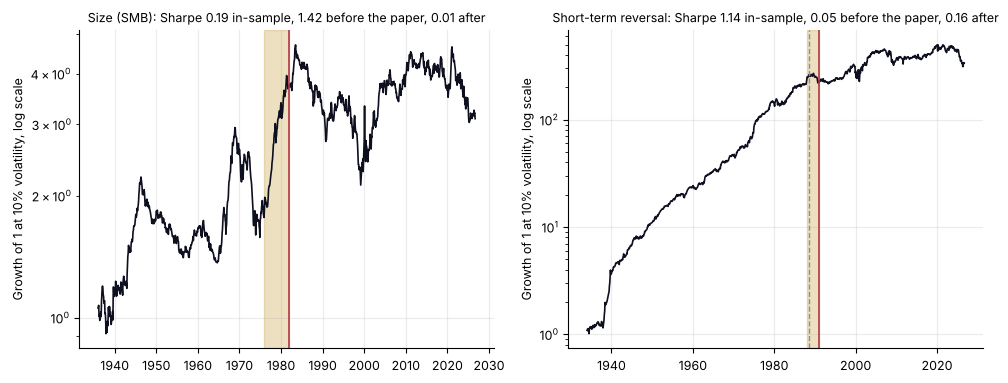

In [16]:
# Figure 1: two stories (size and short-term reversal)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for ax, k in zip(axes, ["smb", "str"]):
    s, first, is_end, post_start = periods(k); s = s[s.index >= first]
    cum = np.exp(np.log1p(s * (10.0 / (s.std() * np.sqrt(12))) / 100).cumsum())
    ax.plot(cum.index.to_timestamp(), cum.values, color=NAVY, lw=1.2); ax.set_yscale("log")
    ax.axvspan((is_end + 1).to_timestamp(), post_start.to_timestamp(), color=GOLD, alpha=.25)
    ax.axvline(post_start.to_timestamp(), color=RED, lw=1.2)
    if k == "str":
        ax.axvline(pd.Period(breaks.loc["str", "break_date"], "M").to_timestamp(), color=GREY, lw=1, ls="--")
    ax.set_title(f"{META[k][0]}: Sharpe {sharpe(seg(s, first, is_end)):.2f} in-sample, {sharpe(seg(s, is_end + 1, post_start - 1)):.2f} before the paper, {sharpe(seg(s, post_start, END)):.2f} after", fontsize=9)
    ax.set_ylabel("Growth of 1 at 10% volatility, log scale")
fig.tight_layout(); fig.savefig(f"{FIG}/figure1_two_stories.png", dpi=200, bbox_inches="tight"); plt.show()

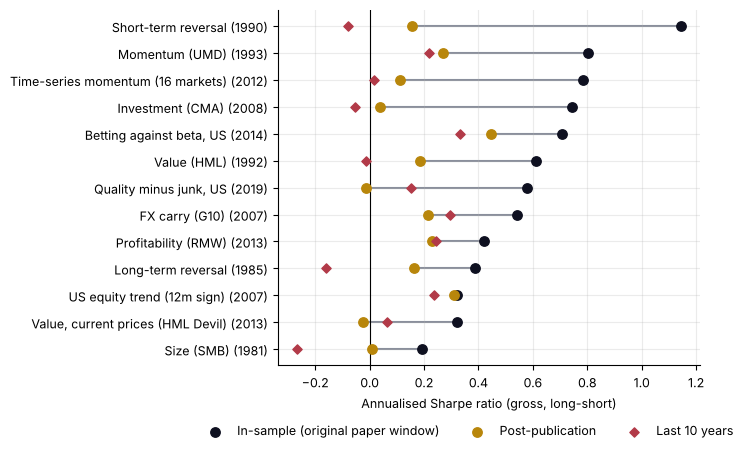

In [17]:
# Figure 2: in-sample vs post-publication vs last 10 years
S = summ.loc[CORE].sort_values("sr_is")
fig, ax = plt.subplots(figsize=(7.2, 4.6))
for i, (k, r) in enumerate(S.iterrows()):
    ax.plot([r.sr_post, r.sr_is], [i, i], color=GREY, lw=1.5, zorder=1)
    ax.scatter(r.sr_is, i, color=NAVY, s=46, zorder=3, label="In-sample (original paper window)" if i == 0 else None)
    ax.scatter(r.sr_post, i, color=GOLD, s=46, zorder=3, label="Post-publication" if i == 0 else None)
    ax.scatter(r.sr_10, i, color=RED, s=22, marker="D", zorder=4, label="Last 10 years" if i == 0 else None)
ax.set_yticks(range(len(S))); ax.set_yticklabels([f"{META[k][0]} ({META[k][1]})" for k in S.index])
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("Annualised Sharpe ratio (gross, long-short)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=3, frameon=False)
fig.tight_layout(); fig.savefig(f"{FIG}/figure2_sharpe_dumbbell.png", dpi=200, bbox_inches="tight"); plt.show()

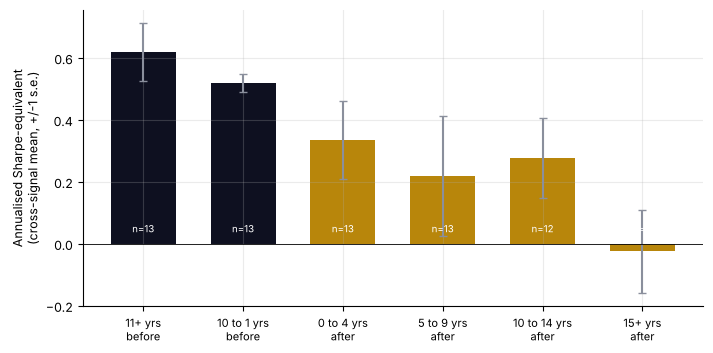

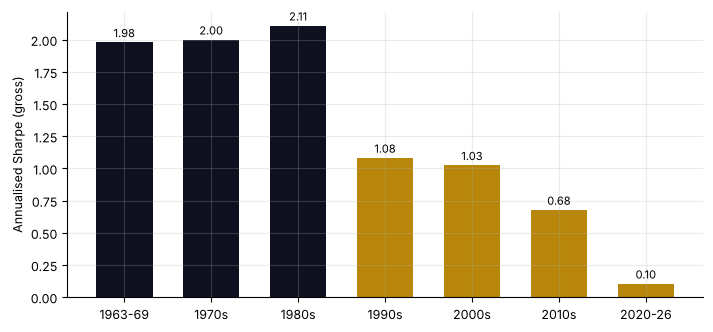

In [18]:
# Figure 3: event study by years relative to publication
fig, ax = plt.subplots(figsize=(7.2, 3.6)); xs = np.arange(len(event_bins))
ax.bar(xs, event_bins["mean_sharpe_equiv"], color=[NAVY if i < 2 else GOLD for i in xs], width=0.65)
ax.errorbar(xs, event_bins["mean_sharpe_equiv"], yerr=event_bins["se"], fmt="none", ecolor=GREY, capsize=3)
for x, n in zip(xs, event_bins["n_signals"]):
    ax.text(x, 0.03, f"n={n}", ha="center", va="bottom", color="white", fontsize=7)
ax.set_xticks(xs); ax.set_xticklabels([b.replace(" yrs ", " yrs\n") for b in event_bins.index], fontsize=8)
ax.axhline(0, color="black", lw=0.6); ax.set_ylabel("Annualised Sharpe-equivalent\n(cross-signal mean, +/-1 s.e.)")
fig.tight_layout(); fig.savefig(f"{FIG}/figure3_event_study.png", dpi=200); plt.show()

# Figure 4: basket by decade
fig, ax = plt.subplots(figsize=(7.2, 3.4)); v = basket_dec["basket of nine"].values
ax.bar(basket_dec.index, v, color=[NAVY] * 3 + [GOLD] * 4, width=0.65)
for i, x in enumerate(v):
    ax.text(i, x + 0.04, f"{x:.2f}", ha="center", fontsize=8)
ax.set_ylabel("Annualised Sharpe (gross)")
fig.tight_layout(); fig.savefig(f"{FIG}/figure4_basket_by_decade.png", dpi=200); plt.show()

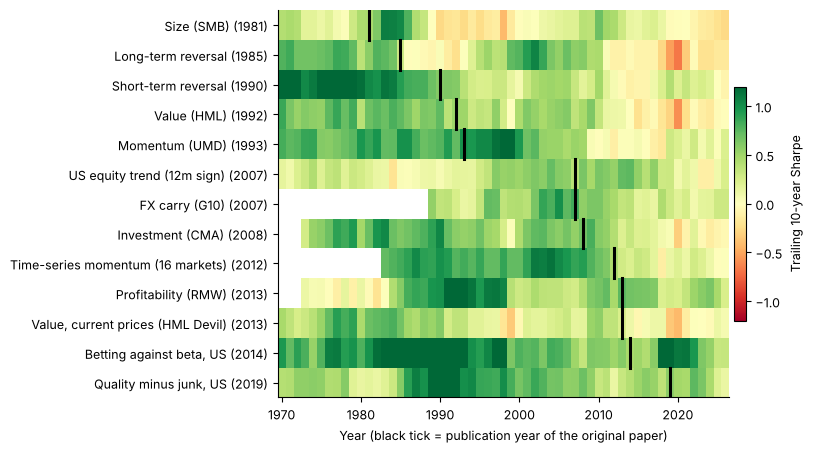

In [19]:
# Figure 5: trailing 10-year Sharpe heatmap
def roll_sharpe(k, w=120):
    s = sig[k].dropna(); return s.rolling(w).mean() / s.rolling(w).std() * np.sqrt(12)
order_pub = sorted(CORE, key=lambda k: META[k][1])
R = pd.DataFrame({k: roll_sharpe(k) for k in CORE}); R = R[R.index >= pd.Period("1970-01", "M")]
Y = R.groupby(R.index.year).last()
fig, ax = plt.subplots(figsize=(8.2, 4.6))
im = ax.imshow(Y[order_pub].T.values, aspect="auto", cmap="RdYlGn", vmin=-1.2, vmax=1.2,
               extent=[Y.index.min() - 0.5, Y.index.max() + 0.5, len(order_pub) - 0.5, -0.5])
ax.set_yticks(range(len(order_pub))); ax.set_yticklabels([f"{META[k][0]} ({META[k][1]})" for k in order_pub]); ax.grid(False)
for i, k in enumerate(order_pub):
    ax.plot([META[k][1]] * 2, [i - 0.5, i + 0.5], color="black", lw=2.2)
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01).set_label("Trailing 10-year Sharpe")
ax.set_xlabel("Year (black tick = publication year of the original paper)")
fig.tight_layout(); fig.savefig(f"{FIG}/figure5_rolling_heatmap.png", dpi=200); plt.show()

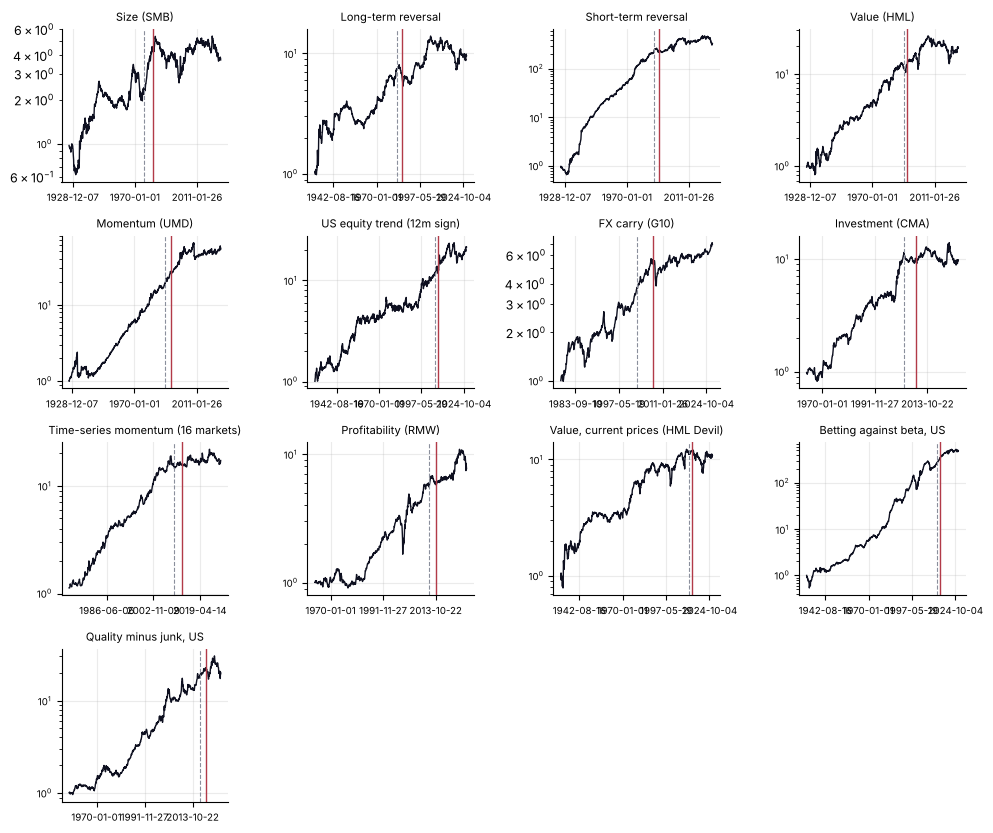

In [20]:
# Figure 6 (appendix): cumulative returns, 10% volatility, log scale
fig, axes = plt.subplots(int(np.ceil(len(CORE) / 4)), 4, figsize=(10, 2.1 * int(np.ceil(len(CORE) / 4))))
for ax, k in zip(axes.ravel(), order_pub):
    s = sig[k].dropna(); cum = np.exp(np.log1p(s * (10.0 / (s.std() * np.sqrt(12))) / 100).cumsum())
    ax.plot(cum.index.to_timestamp(), cum.values, color=NAVY, lw=1); ax.set_yscale("log")
    lab, pub, o0, o1, _ = META[k]
    ax.axvline(pd.Timestamp(f"{o1}-12-31"), color=GREY, lw=0.8, ls="--"); ax.axvline(pd.Timestamp(f"{pub}-12-31"), color=RED, lw=1.0)
    ax.set_title(lab, fontsize=8); ax.tick_params(labelsize=7); ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(4))
for ax in axes.ravel()[len(CORE):]:
    ax.axis("off")
fig.tight_layout(); fig.savefig(f"{FIG}/figure6_cumulative_appendix.png", dpi=200); plt.show()

## 11. Hero image

Short-term reversal, 1934 to 2026, cumulative return at 10% volatility on a log axis. A marker sits at the estimated break (August 1988). No text, per the Medium layout.

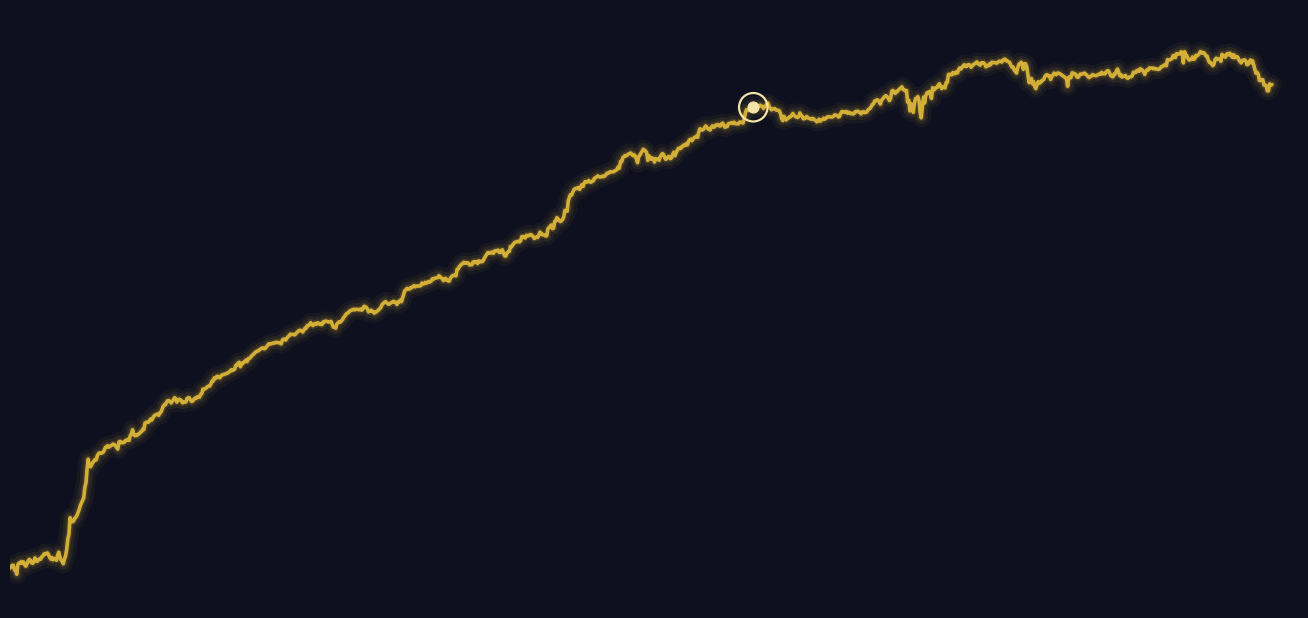

In [21]:
s, first, is_end, post_start = periods("str")
s = s[s.index >= first]
cum = np.exp(np.log1p(s * (10.0 / (s.std() * np.sqrt(12))) / 100).cumsum())
x = cum.index.to_timestamp(); yv = np.log(cum.values)
fig = plt.figure(figsize=(14, 7.875), facecolor="#0E1020"); ax = fig.add_axes([0.04, 0.12, 0.92, 0.76]); ax.set_facecolor("#0E1020")
for lw, a in [(14, .05), (9, .09), (5, .16)]:                       # soft glow
    ax.plot(x, yv, color="#D4AF37", lw=lw, alpha=a, solid_capstyle="round")
ax.plot(x, yv, color="#D4AF37", lw=2.6, solid_capstyle="round")
b = pd.Period(breaks.loc["str", "break_date"], "M").to_timestamp()
by = yv[x.get_indexer([b], method="nearest")[0]]
ax.scatter([b], [by], s=420, facecolors="none", edgecolors="#F3E3A6", linewidths=1.6, zorder=5)
ax.scatter([b], [by], s=60, color="#F3E3A6", zorder=6)
ax.set_xlim(x.min(), x.max() + pd.Timedelta(days=700)); ax.set_ylim(yv.min() - 0.4, yv.max() + 0.5)
ax.axis("off")
fig.savefig(f"{FIG}/hero.png", dpi=200, facecolor="#0E1020"); plt.show()